In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')
%cd /content/drive/MyDrive/Colab_AI 영상처리

Mounted at /content/drive
/content/drive/MyDrive/Colab_AI 영상처리


In [2]:
Image_Path = Path('picture/sheep.jpg')
assert Image_Path.exists(), '이미지가 없습니다.'

In [3]:
sheep =cv2.imread(str(Image_Path))
if sheep is None:
  raise FileNotFoundError('이미지를 읽지 못했습니다.')

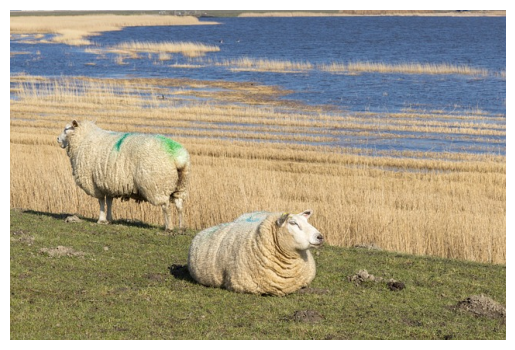

In [17]:
sheep_rgb = cv2.cvtColor(
    sheep,
    cv2.COLOR_BGR2RGB
)
plt.imshow(sheep_rgb)
plt.axis('off')
plt.show()

# cv2.GaussianBlur() :: 가우시안 블러 (이미지 블러 처리)
필요하지 않은 정보를 흐릿하게 -> 효율적인 연산 유도

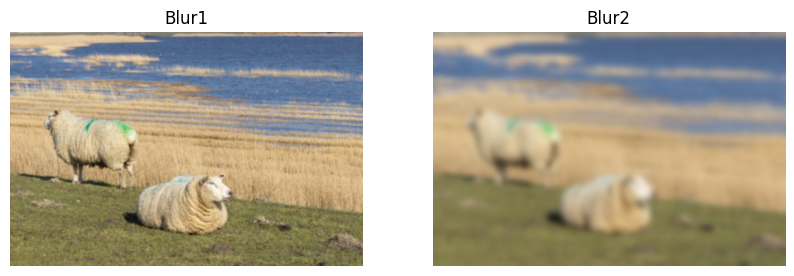

In [7]:
blur_image = cv2.GaussianBlur(sheep_rgb, (5, 5), 0)
blur_image2 = cv2.GaussianBlur(sheep_rgb, (35, 35), 0)

# 2개의 블러 사진, 옆으로 나란하게 작성
plt.figure(figsize = (10, 5))

plt.subplot(1, 2, 1)
plt.imshow(blur_image)
plt.axis('off')
plt.title('Blur1')

plt.subplot(1, 2, 2)
plt.imshow(blur_image2)
plt.axis('off')
plt.title('Blur2')

plt.show()

In [8]:
print(sheep_rgb[0][0])      # 원본
print(blur_image[0][0])     # 약한 블러 처리
print(blur_image2[0][0])    # 강한 블러 처리

# 블러가 강할수록, 빨강/파랑/초록 수치가 특정 값으로 수렴

[107 132 163]
[130 146 168]
[158 155 146]


# cv2.Canny() :: 경계선 검출

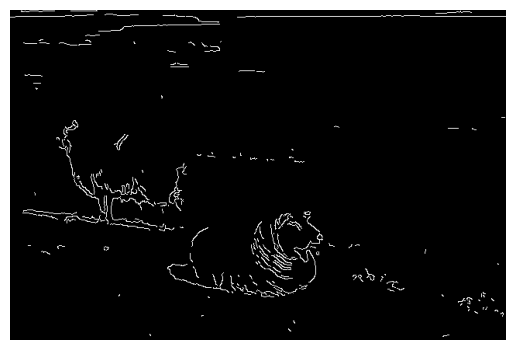

In [12]:
# 색상 정보, 높은 해상도는 경계선 검출에 있어 장애물
#   => 흑백+블러 처리된 이미지로 작업

# 1. 흑백 이미지로 변환 (색상은 방해)
gray_image = cv2.cvtColor(
    blur_image,
    cv2.COLOR_RGB2GRAY
)

# 2. 경계선 검출 진행
c1 = cv2.Canny(gray_image, 30, 150)     # Canny(이미지, 하한선, 상한선)
c2 = cv2.Canny(gray_image, 150, 200)
  # 150 미만인 픽셀값 경계선X, 200 초과하는 픽셀값 경계선O
  # 150~200 -> 주변의 픽셀값에 따라 경계선인지 결정

plt.imshow(c2, cmap='gray')
plt.axis('off')
plt.show()

# cv2.rectangle() :: 이미지 위에 사각형 그리기

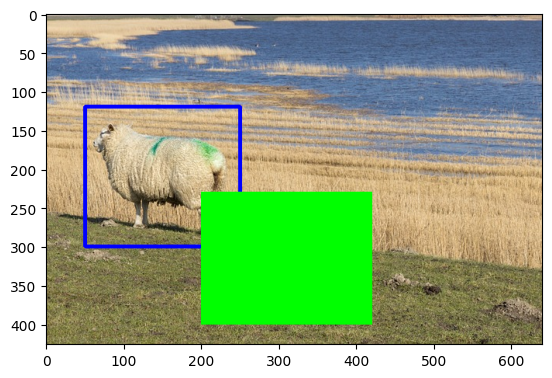

In [27]:
# cv2.rectangle(이미지, 사각형_시작점, 사각형_종료점, 테두리_색상, 테두리_굵기)
sheep_rgb = cv2.cvtColor(
    sheep,
    cv2.COLOR_BGR2RGB
)
sheep_copy = sheep_rgb.copy()

# 좌표 설정 :: (너비 번호, 높이 번호)
cv2.rectangle(sheep_copy, (50, 120), (250, 300), (0, 0, 255), 3)
cv2.rectangle(sheep_copy, (200, 230), (420, 400), (0, 255, 0), -1)
# 테두리 값이 -1이면, 사각형 내부 채우기

plt.imshow(sheep_copy)
plt.show()

# 격자 눈금 참고해서, 양 2마리 사각형 그리기